In [1]:
import pandas as pd
from pathlib import Path

files = sorted([f.name for f in Path("data").iterdir() if f.is_file()])
df = pd.concat([
    pd.read_csv(f"data/{file}") for file in files
])

df

,open_time,open,high,low,close,volume,close_time,quote_volume,count,taker_buy_volume,taker_buy_quote_volume,ignore
0,1577836800000,129.12,129.12,128.76,128.81,2438.197,1577837099999,3.143663e+05,151,1127.136,1.453314e+05,0
1,1577837100000,128.78,128.94,128.65,128.87,2126.484,1577837399999,2.738965e+05,164,1377.615,1.774575e+05,0
2,1577837400000,128.90,128.92,128.77,128.87,888.920,1577837699999,1.145148e+05,95,487.341,6.277934e+04,0
3,1577837700000,128.88,128.99,128.77,128.82,1570.849,1577837999999,2.024439e+05,113,688.471,8.873060e+04,0
4,1577838000000,128.81,128.85,128.66,128.67,621.585,1577838299999,8.003575e+04,57,360.833,4.645903e+04,0
...,...,...,...,...,...,...,...,...,...,...,...,...
8635,1782862500000,1571.00,1571.00,1569.23,1569.24,2978.315,1782862799999,4.676017e+06,6135,1627.408,2.555045e+06,0
8636,1782862800000,1569.23,1570.27,1568.61,1570.14,3609.242,1782863099999,5.664026e+06,6748,1773.936,2.783775e+06,0
8637,1782863100000,1570.15,1572.21,1569.67,1570.39,14444.464,1782863399999,2.269243e+07,14558,9666.018,1.518565e+07,0
8638,1782863400000,1570.39,1571.14,1569.60,1571.11,6822.251,1782863699999,1.071485e+07,10540,4129.600,6.486000e+06,0


In [2]:
import numpy as np

INTERVAL_MS = 5 * 60 * 1000  # 5 minutes in ms

# Assert continuous open time
diff = np.diff(df["open_time"].to_numpy())
assert np.all(diff == INTERVAL_MS), (
    f"Found {np.sum(diff != INTERVAL_MS)} discontinuities.\n"
    f"First few indices: {np.where(diff != INTERVAL_MS)[0][:10]}"
)

In [3]:
import torch
from torch.utils.data import Dataset, DataLoader

class CryptoDeltaDataset(Dataset):
    def __init__(self, df: pd.DataFrame, past_window: int, future_window: int, eps=1e-9):
        self.past_window = past_window
        self.future_window = future_window
        self.eps = eps

        self.df = df.reset_index(drop=True)
        self.features = ["open", "high", "low", "close", "volume", "count"]

        values = torch.tensor(self.df[self.features].values)
        diff = values[1:] - values[:-1]
        self.deltas = torch.log2(diff.abs() + 1) * torch.sign(diff)

        self.min_deltas = self.deltas.min(dim=0).values.unsqueeze(0)
        self.max_deltas = self.deltas.max(dim=0).values.unsqueeze(0)

    def __len__(self):
        return len(self.deltas) - self.past_window - self.future_window

    def __getitem__(self, idx):
        delta = self.deltas[idx:idx + self.future_window + self.past_window]

        # Normalize to [0, 1]
        normalized = ((delta - self.min_deltas) / (self.max_deltas - self.min_deltas + self.eps)).to(torch.float32)

        return (normalized[:self.past_window], normalized[self.past_window:])

    def collate_fn(self, batch):
        return [torch.stack(d, dim=0) for d in zip(*batch)]

dataset = CryptoDeltaDataset(df, past_window=12*24*7, future_window=12*24*7)
dataloader = DataLoader(dataset=dataset, batch_size=2, collate_fn=dataset.collate_fn)

next(iter(dataloader))[0]

tensor([[[0.4855, 0.4723, 0.4859, 0.5127, 0.3032, 0.5998],
         [0.5176, 0.4857, 0.5029, 0.5081, 0.2538, 0.3427],
         [0.5071, 0.4937, 0.4940, 0.5043, 0.7443, 0.6112],
         ...,
         [0.4956, 0.4621, 0.4667, 0.4930, 0.2193, 0.3081],
         [0.4904, 0.4755, 0.4866, 0.4832, 0.3130, 0.3286],
         [0.4837, 0.5177, 0.4880, 0.5478, 0.7981, 0.7268]],

        [[0.5176, 0.4857, 0.5029, 0.5081, 0.2538, 0.3427],
         [0.5071, 0.4937, 0.4940, 0.5043, 0.7443, 0.6112],
         [0.5033, 0.4755, 0.4859, 0.4971, 0.2633, 0.3504],
         ...,
         [0.4904, 0.4755, 0.4866, 0.4832, 0.3130, 0.3286],
         [0.4837, 0.5177, 0.4880, 0.5478, 0.7981, 0.7268],
         [0.5483, 0.5377, 0.5372, 0.5428, 0.8216, 0.7428]]])

In [4]:
# ============================================================
# FULL MODEL DEFINITIONS — FLEXATTENTION ONLY
# ============================================================

from __future__ import annotations

from copy import deepcopy
from typing import Any, Callable

import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.attention.flex_attention import (
    BlockMask,
    create_block_mask,
    flex_attention,
)
from torch.utils.checkpoint import checkpoint

flex_attention = torch.compile(flex_attention)


# ============================================================
# Environment
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is required for this FlexAttention training implementation."
    )

DEVICE = torch.device("cuda")

# T4 supports FP16 well. It does not support native BF16 tensor-core training.
AMP_DTYPE = torch.float16


# ============================================================
# Utilities
# ============================================================

def count_parameters(model: nn.Module) -> tuple[int, int]:
    total = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    return total, trainable


# ============================================================
# RoPE
# ============================================================

class SimpleRoPE(nn.Module):
    def __init__(
        self,
        dim: int,
        max_seq_len: int = 2048,
        base: float = 10_000.0,
    ) -> None:
        super().__init__()

        if dim % 2 != 0:
            raise ValueError(
                f"RoPE dimension must be even, received {dim}."
            )

        inv_freq = 1.0 / (
            base ** (
                torch.arange(
                    0,
                    dim,
                    2,
                    dtype=torch.float32,
                ) / dim
            )
        )

        positions = torch.arange(
            max_seq_len,
            dtype=torch.float32,
        )

        frequencies = torch.outer(
            positions,
            inv_freq,
        )

        embedding = torch.cat(
            (frequencies, frequencies),
            dim=-1,
        )

        self.register_buffer(
            "cos",
            embedding.cos()[None, None, :, :],
            persistent=False,
        )

        self.register_buffer(
            "sin",
            embedding.sin()[None, None, :, :],
            persistent=False,
        )

    @staticmethod
    def _rotate_half(
        x: torch.Tensor,
    ) -> torch.Tensor:
        x1, x2 = x.chunk(2, dim=-1)

        return torch.cat(
            (-x2, x1),
            dim=-1,
        )

    def forward(
        self,
        q: torch.Tensor,
        k: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        sequence_length = q.shape[-2]

        if sequence_length > self.cos.shape[-2]:
            raise ValueError(
                f"Sequence length {sequence_length} exceeds "
                f"RoPE capacity {self.cos.shape[-2]}."
            )

        cos = self.cos[
            :, :, :sequence_length, :
        ].to(
            device=q.device,
            dtype=q.dtype,
        )

        sin = self.sin[
            :, :, :sequence_length, :
        ].to(
            device=q.device,
            dtype=q.dtype,
        )

        q = (
            q * cos
            + self._rotate_half(q) * sin
        )

        k = (
            k * cos
            + self._rotate_half(k) * sin
        )

        return q, k


# ============================================================
# Gated short convolution
# ============================================================

class GatedShortConv(nn.Module):
    def __init__(
        self,
        embed_dim: int,
        window_size: int,
        bias: bool = True,
    ) -> None:
        super().__init__()

        if window_size < 1:
            raise ValueError(
                "window_size must be positive."
            )

        if window_size % 2 != 1:
            raise ValueError(
                "window_size must be odd."
            )

        self.window_size = window_size

        self.in_proj = nn.Linear(
            embed_dim,
            3 * embed_dim,
            bias=bias,
        )

        self.conv = nn.Conv1d(
            in_channels=embed_dim,
            out_channels=embed_dim,
            kernel_size=window_size,
            groups=embed_dim,
            bias=bias,
        )

        self.out_proj = nn.Linear(
            embed_dim,
            embed_dim,
            bias=bias,
        )

    def forward(
        self,
        x: torch.Tensor,
        causal: bool = False,
    ) -> torch.Tensor:
        gate_in, gate_out, values = (
            self.in_proj(x).chunk(
                3,
                dim=-1,
            )
        )

        values = (
            gate_in * values
        ).transpose(1, 2)

        if causal:
            values = F.pad(
                values,
                (
                    self.window_size - 1,
                    0,
                ),
            )
        else:
            half_window = (
                self.window_size // 2
            )

            values = F.pad(
                values,
                (
                    half_window,
                    half_window,
                ),
            )

        values = self.conv(values)
        values = values.transpose(1, 2)

        return self.out_proj(
            gate_out * values
        )


# ============================================================
# FlexAttention-only attention
# ============================================================

class HybridAttention(nn.Module):
    """
    FlexAttention-only attention.

    There is:
        - no F.scaled_dot_product_attention call
        - no dense boolean attention matrix
        - no SDPA selection path

    causal=True:
        kv_idx <= q_idx
        q_idx - kv_idx < window_size

    causal=False:
        abs(q_idx - kv_idx) < window_size

    Important:
        Call prepare_block_mask(device) before compiling/executing.
        Forward refuses eager execution so an accidental uncompiled path
        cannot be used.
    """

    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        max_seq_len: int,
        window_size: int,
        causal: bool,
        bias: bool = True,
        block_size: int = 128,
    ) -> None:
        super().__init__()

        if embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim={embed_dim} must be divisible by "
                f"num_heads={num_heads}."
            )

        if max_seq_len < 1:
            raise ValueError(
                "max_seq_len must be positive."
            )

        if window_size < 1:
            raise ValueError(
                "window_size must be positive."
            )

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = (
            embed_dim // num_heads
        )

        self.max_seq_len = max_seq_len
        self.window_size = min(
            window_size,
            max_seq_len,
        )

        self.causal = causal
        self.block_size = block_size

        self.qkv_proj = nn.Linear(
            embed_dim,
            3 * embed_dim,
            bias=bias,
        )

        self.o_proj = nn.Linear(
            embed_dim,
            embed_dim,
            bias=bias,
        )

        self.rope = SimpleRoPE(
            dim=self.head_dim,
            max_seq_len=max_seq_len,
        )

        self.block_mask: BlockMask | None = None
        self.block_mask_device: torch.device | None = None

    def _mask_mod(
        self,
    ) -> Callable:
        window_size = self.window_size

        if self.causal:
            def causal_sliding_window(
                batch_index,
                head_index,
                query_index,
                key_value_index,
            ):
                del batch_index, head_index

                is_causal = (
                    key_value_index
                    <= query_index
                )

                is_inside_window = (
                    query_index
                    - key_value_index
                    < window_size
                )

                return (
                    is_causal
                    & is_inside_window
                )

            return causal_sliding_window

        def bidirectional_sliding_window(
            batch_index,
            head_index,
            query_index,
            key_value_index,
        ):
            del batch_index, head_index

            return (
                query_index
                - key_value_index
            ).abs() < window_size

        return bidirectional_sliding_window

    @torch.no_grad()
    def prepare_block_mask(
        self,
        device: torch.device | str,
    ) -> None:
        device = torch.device(device)

        if device.type != "cuda":
            raise RuntimeError(
                "FlexAttention training requires CUDA."
            )

        if device.index is None:
            device = torch.device(
                "cuda",
                torch.cuda.current_device(),
            )

        self.block_mask = create_block_mask(
            self._mask_mod(),
            B=None,
            H=None,
            Q_LEN=self.max_seq_len,
            KV_LEN=self.max_seq_len,
            device=device,
            BLOCK_SIZE=self.block_size,
        )

        self.block_mask_device = device

    def _split_heads(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        return (
            x.unflatten(
                -1,
                (
                    self.num_heads,
                    self.head_dim,
                ),
            )
            .transpose(1, 2)
            .contiguous()
        )

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        sequence_length = x.shape[1]

        if sequence_length != self.max_seq_len:
            raise ValueError(
                f"FlexAttention was prepared for fixed sequence length "
                f"{self.max_seq_len}, received {sequence_length}."
            )

        if self.block_mask is None:
            raise RuntimeError(
                "BlockMask is not prepared. Call "
                "model.prepare_flex_attention(device) before torch.compile."
            )

        q, k, v = self.qkv_proj(x).chunk(
            3,
            dim=-1,
        )

        q = self._split_heads(q)
        k = self._split_heads(k)
        v = self._split_heads(v)

        q, k = self.rope(q, k)

        attention_output = flex_attention(
            q,
            k,
            v,
            block_mask=self.block_mask,
            kernel_options={
                "ROWS_GUARANTEED_SAFE": True,
                "BLOCKS_ARE_CONTIGUOUS": True,
            },
        )

        attention_output = (
            attention_output
            .transpose(1, 2)
            .contiguous()
            .flatten(-2)
        )

        return self.o_proj(
            attention_output
        )


# ============================================================
# SwiGLU
# ============================================================

class SwiGLU(nn.Module):
    def __init__(
        self,
        embed_dim: int,
        hidden_multiplier: float = 8 / 3,
        bias: bool = False,
    ) -> None:
        super().__init__()

        hidden_dim = int(
            embed_dim
            * hidden_multiplier
        )

        self.hidden_dim = hidden_dim

        self.in_proj = nn.Linear(
            embed_dim,
            2 * hidden_dim,
            bias=bias,
        )

        self.out_proj = nn.Linear(
            hidden_dim,
            embed_dim,
            bias=bias,
        )

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        gate, value = (
            self.in_proj(x).chunk(
                2,
                dim=-1,
            )
        )

        return self.out_proj(
            F.silu(gate) * value
        )


# ============================================================
# Blocks
# ============================================================

class HybridAttentionBlock(nn.Module):
    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        max_seq_len: int,
        window_size: int,
        causal: bool,
        hidden_multiplier: float = 8 / 3,
        bias: bool = True,
        flex_block_size: int = 128,
    ) -> None:
        super().__init__()

        self.mixer_in_norm = nn.RMSNorm(
            embed_dim
        )

        self.mixer = HybridAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            max_seq_len=max_seq_len,
            window_size=window_size,
            causal=causal,
            bias=bias,
            block_size=flex_block_size,
        )

        self.mixer_out_norm = nn.RMSNorm(
            embed_dim
        )

        self.mlp_in_norm = nn.RMSNorm(
            embed_dim
        )

        self.mlp = SwiGLU(
            embed_dim=embed_dim,
            hidden_multiplier=hidden_multiplier,
            bias=bias,
        )

        self.mlp_out_norm = nn.RMSNorm(
            embed_dim
        )

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        x = x + self.mixer_out_norm(
            self.mixer(
                self.mixer_in_norm(x)
            )
        )

        x = x + self.mlp_out_norm(
            self.mlp(
                self.mlp_in_norm(x)
            )
        )

        return x


class GatedShortConvBlock(nn.Module):
    def __init__(
        self,
        embed_dim: int,
        window_size: int,
        hidden_multiplier: float = 8 / 3,
        bias: bool = True,
    ) -> None:
        super().__init__()

        self.mixer_in_norm = nn.RMSNorm(
            embed_dim
        )

        self.mixer = GatedShortConv(
            embed_dim=embed_dim,
            window_size=window_size,
            bias=bias,
        )

        self.mixer_out_norm = nn.RMSNorm(
            embed_dim
        )

        self.mlp_in_norm = nn.RMSNorm(
            embed_dim
        )

        self.mlp = SwiGLU(
            embed_dim=embed_dim,
            hidden_multiplier=hidden_multiplier,
            bias=bias,
        )

        self.mlp_out_norm = nn.RMSNorm(
            embed_dim
        )

    def forward(
        self,
        x: torch.Tensor,
        causal: bool = False,
    ) -> torch.Tensor:
        x = x + self.mixer_out_norm(
            self.mixer(
                self.mixer_in_norm(x),
                causal=causal,
            )
        )

        x = x + self.mlp_out_norm(
            self.mlp(
                self.mlp_in_norm(x)
            )
        )

        return x


# ============================================================
# Generated target network
# ============================================================

class GeneratedTargetNetwork(nn.Module):
    """
    Generated causal policy.

    Every attention layer is FlexAttention-only.
    The policy sequence length is fixed to max_seq_len.
    """

    def __init__(
        self,
        in_features: int,
        out_features: int,
        embed_dim: int,
        num_heads: int,
        hidden_multiplier: float,
        conv_window_size: int,
        attn_window_size: int,
        num_conv_layers: int,
        num_attn_layers: int,
        max_seq_len: int,
        bias: bool = True,
        flex_block_size: int = 128,
    ) -> None:
        super().__init__()

        if embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim={embed_dim} must be divisible by "
                f"num_heads={num_heads}."
            )

        self.in_features = in_features
        self.out_features = out_features
        self.embed_dim = embed_dim
        self.max_seq_len = max_seq_len

        self.expand_layer = nn.Linear(
            in_features,
            embed_dim,
            bias=bias,
        )

        self.conv_blocks = nn.ModuleList([
            GatedShortConvBlock(
                embed_dim=embed_dim,
                window_size=conv_window_size,
                hidden_multiplier=hidden_multiplier,
                bias=bias,
            )
            for _ in range(
                num_conv_layers
            )
        ])

        self.attn_blocks = nn.ModuleList([
            HybridAttentionBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                max_seq_len=max_seq_len,
                window_size=attn_window_size,
                causal=True,
                hidden_multiplier=hidden_multiplier,
                bias=bias,
                flex_block_size=flex_block_size,
            )
            for _ in range(
                num_attn_layers
            )
        ])

        self.final_norm = nn.RMSNorm(
            embed_dim
        )

        self.out_proj = nn.Linear(
            embed_dim,
            out_features,
            bias=bias,
        )

    @torch.no_grad()
    def prepare_flex_attention(
        self,
        device: torch.device | str,
    ) -> None:
        for block in self.attn_blocks:
            block.mixer.prepare_block_mask(
                device
            )

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        if x.ndim != 3:
            raise ValueError(
                f"Expected [batch, sequence, features], "
                f"received {tuple(x.shape)}."
            )

        if x.shape[-1] != self.in_features:
            raise ValueError(
                f"Expected {self.in_features} input features, "
                f"received {x.shape[-1]}."
            )

        if x.shape[1] != self.max_seq_len:
            raise ValueError(
                f"Expected fixed sequence length {self.max_seq_len}, "
                f"received {x.shape[1]}."
            )

        x = self.expand_layer(x)

        for block in self.conv_blocks:
            x = block(
                x,
                causal=True,
            )

        for block in self.attn_blocks:
            x = block(x)

        x = self.final_norm(x)

        return self.out_proj(x)

    @torch.no_grad()
    def apply_generated_weights(
        self,
        generated_state_dict: dict[
            str,
            torch.Tensor,
        ],
        *,
        strict: bool = True,
        freeze: bool = True,
    ) -> None:
        target_parameters = dict(
            self.named_parameters()
        )

        if strict:
            missing = (
                set(target_parameters)
                - set(generated_state_dict)
            )

            unexpected = (
                set(generated_state_dict)
                - set(target_parameters)
            )

            if missing:
                raise KeyError(
                    f"Missing generated parameters: "
                    f"{sorted(missing)}"
                )

            if unexpected:
                raise KeyError(
                    f"Unexpected generated parameters: "
                    f"{sorted(unexpected)}"
                )

        for name, parameter in (
            target_parameters.items()
        ):
            if name not in generated_state_dict:
                continue

            generated = (
                generated_state_dict[name]
                .detach()
                .to(
                    device=parameter.device,
                    dtype=parameter.dtype,
                )
            )

            if generated.shape != parameter.shape:
                raise ValueError(
                    f"Shape mismatch for {name}: "
                    f"expected {tuple(parameter.shape)}, "
                    f"received {tuple(generated.shape)}."
                )

            parameter.copy_(generated)
            parameter.requires_grad_(
                not freeze
            )

    def detached_copy_with_weights(
        self,
        generated_state_dict: dict[
            str,
            torch.Tensor,
        ],
    ) -> "GeneratedTargetNetwork":
        result = deepcopy(self)

        result.apply_generated_weights(
            generated_state_dict,
            strict=True,
            freeze=True,
        )

        return result


# ============================================================
# Strategy hypernetwork
# ============================================================

class StrategyNetwork(nn.Module):
    """
    Hypernetwork flow:

        [B, past_window, features]
            -> full-resolution convolution stack
            -> contiguous group pooling
            -> FlexAttention over group embeddings
            -> generated target parameters

    Group mapping:
        4 groups per generated convolution block
        3 groups per generated attention block
    """

    def __init__(
        self,
        in_features: int,
        embed_dim: int,
        num_heads: int,
        conv_window_size: int,
        attn_window_size: int,
        num_conv_layers: int,
        num_attn_layers: int,
        max_seq_len: int,

        target_network_out_features: int,
        target_network_embed_dim: int,
        target_network_num_heads: int,
        target_network_hidden_multiplier: float,
        target_network_conv_window_size: int,
        target_network_attn_window_size: int,
        target_network_group_size: int,
        target_network_num_conv_layers: int,
        target_network_num_attn_layers: int,
        target_network_max_seq_len: int,

        hidden_multiplier: float = 8 / 3,
        bias: bool = True,
        flex_block_size: int = 128,
        gradient_checkpointing: bool = True,
    ) -> None:
        super().__init__()

        if embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim={embed_dim} must be divisible by "
                f"num_heads={num_heads}."
            )

        if (
            max_seq_len
            % target_network_group_size
            != 0
        ):
            raise ValueError(
                f"max_seq_len={max_seq_len} must be divisible by "
                f"group_size={target_network_group_size}."
            )

        number_of_groups = (
            max_seq_len
            // target_network_group_size
        )

        required_groups = (
            4
            * target_network_num_conv_layers
            + 3
            * target_network_num_attn_layers
        )

        if number_of_groups != required_groups:
            raise ValueError(
                f"Received {number_of_groups} groups, but the target "
                f"network requires {required_groups}: "
                f"4×{target_network_num_conv_layers} + "
                f"3×{target_network_num_attn_layers}."
            )

        self.in_features = in_features
        self.embed_dim = embed_dim
        self.input_seq_len = max_seq_len

        self.group_size = (
            target_network_group_size
        )

        self.num_groups = (
            number_of_groups
        )

        self.target_num_conv_layers = (
            target_network_num_conv_layers
        )

        self.target_num_attn_layers = (
            target_network_num_attn_layers
        )

        self.gradient_checkpointing = (
            gradient_checkpointing
        )

        self.target_config: dict[
            str,
            Any,
        ] = {
            "in_features": in_features,
            "out_features": target_network_out_features,
            "embed_dim": target_network_embed_dim,
            "num_heads": target_network_num_heads,
            "hidden_multiplier": target_network_hidden_multiplier,
            "conv_window_size": target_network_conv_window_size,
            "attn_window_size": target_network_attn_window_size,
            "num_conv_layers": target_network_num_conv_layers,
            "num_attn_layers": target_network_num_attn_layers,
            "max_seq_len": target_network_max_seq_len,
            "bias": bias,
            "flex_block_size": flex_block_size,
        }

        self.expand_layer = nn.Linear(
            in_features,
            embed_dim,
            bias=bias,
        )

        self.conv_blocks = nn.ModuleList([
            GatedShortConvBlock(
                embed_dim=embed_dim,
                window_size=conv_window_size,
                hidden_multiplier=hidden_multiplier,
                bias=bias,
            )
            for _ in range(
                num_conv_layers
            )
        ])

        self.attn_blocks = nn.ModuleList([
            HybridAttentionBlock(
                embed_dim=embed_dim,
                num_heads=num_heads,
                max_seq_len=number_of_groups,
                window_size=min(
                    attn_window_size,
                    number_of_groups,
                ),
                causal=False,
                hidden_multiplier=hidden_multiplier,
                bias=bias,
                flex_block_size=flex_block_size,
            )
            for _ in range(
                num_attn_layers
            )
        ])

        self.final_norm = nn.RMSNorm(
            embed_dim
        )

        target_dim = (
            target_network_embed_dim
        )

        target_hidden_dim = int(
            target_dim
            * target_network_hidden_multiplier
        )

        self.global_generators = nn.ModuleDict({
            "expand_weight": nn.Linear(
                embed_dim,
                target_dim * in_features,
            ),

            "expand_bias": nn.Linear(
                embed_dim,
                target_dim,
            ),

            "final_norm": nn.Linear(
                embed_dim,
                target_dim,
            ),

            "out_weight": nn.Linear(
                embed_dim,
                target_network_out_features
                * target_dim,
            ),

            "out_bias": nn.Linear(
                embed_dim,
                target_network_out_features,
            ),
        })

        self.generators = nn.ModuleDict({
            "norm": nn.Linear(
                embed_dim,
                target_dim,
            ),

            "triple_weight": nn.Linear(
                embed_dim,
                3
                * target_dim
                * target_dim,
            ),

            "triple_bias": nn.Linear(
                embed_dim,
                3 * target_dim,
            ),

            "square_weight": nn.Linear(
                embed_dim,
                target_dim * target_dim,
            ),

            "square_bias": nn.Linear(
                embed_dim,
                target_dim,
            ),

            "conv_weight": nn.Linear(
                embed_dim,
                target_dim
                * target_network_conv_window_size,
            ),

            "conv_bias": nn.Linear(
                embed_dim,
                target_dim,
            ),

            "mlp_in_weight": nn.Linear(
                embed_dim,
                2
                * target_hidden_dim
                * target_dim,
            ),

            "mlp_in_bias": nn.Linear(
                embed_dim,
                2 * target_hidden_dim,
            ),

            "mlp_out_weight": nn.Linear(
                embed_dim,
                target_dim
                * target_hidden_dim,
            ),

            "mlp_out_bias": nn.Linear(
                embed_dim,
                target_dim,
            ),
        })

        self._initialize_generators()

    @torch.no_grad()
    def prepare_flex_attention(
        self,
        device: torch.device | str,
    ) -> None:
        for block in self.attn_blocks:
            block.mixer.prepare_block_mask(
                device
            )

    @torch.no_grad()
    def _initialize_generators(
        self,
    ) -> None:
        all_generators = [
            *self.global_generators.values(),
            *self.generators.values(),
        ]

        for generator in all_generators:
            nn.init.normal_(
                generator.weight,
                mean=0.0,
                std=1e-4,
            )

            if generator.bias is not None:
                nn.init.zeros_(
                    generator.bias
                )

        nn.init.ones_(
            self.global_generators[
                "final_norm"
            ].bias
        )

        nn.init.ones_(
            self.generators[
                "norm"
            ].bias
        )

    def _run_conv_block(
        self,
        block: GatedShortConvBlock,
        x: torch.Tensor,
    ) -> torch.Tensor:
        if (
            self.training
            and self.gradient_checkpointing
        ):
            return checkpoint(
                lambda hidden: block(
                    hidden,
                    causal=False,
                ),
                x,
                use_reentrant=False,
            )

        return block(
            x,
            causal=False,
        )

    def _run_attention_block(
        self,
        block: HybridAttentionBlock,
        x: torch.Tensor,
    ) -> torch.Tensor:
        if (
            self.training
            and self.gradient_checkpointing
        ):
            return checkpoint(
                block,
                x,
                use_reentrant=False,
            )

        return block(x)

    def _generate_norm(
        self,
        latent: torch.Tensor,
    ) -> torch.Tensor:
        return self.generators[
            "norm"
        ](latent)

    def _generate_triple_projection(
        self,
        latent: torch.Tensor,
    ) -> tuple[
        torch.Tensor,
        torch.Tensor,
    ]:
        target_dim = self.target_config[
            "embed_dim"
        ]

        weight = self.generators[
            "triple_weight"
        ](latent).reshape(
            3 * target_dim,
            target_dim,
        )

        bias = self.generators[
            "triple_bias"
        ](latent)

        return weight, bias

    def _generate_square_projection(
        self,
        latent: torch.Tensor,
    ) -> tuple[
        torch.Tensor,
        torch.Tensor,
    ]:
        target_dim = self.target_config[
            "embed_dim"
        ]

        weight = self.generators[
            "square_weight"
        ](latent).reshape(
            target_dim,
            target_dim,
        )

        bias = self.generators[
            "square_bias"
        ](latent)

        return weight, bias

    def _generate_mlp(
        self,
        latent: torch.Tensor,
    ) -> dict[
        str,
        torch.Tensor,
    ]:
        target_dim = self.target_config[
            "embed_dim"
        ]

        target_hidden_dim = int(
            target_dim
            * self.target_config[
                "hidden_multiplier"
            ]
        )

        return {
            "in_weight": self.generators[
                "mlp_in_weight"
            ](latent).reshape(
                2 * target_hidden_dim,
                target_dim,
            ),

            "in_bias": self.generators[
                "mlp_in_bias"
            ](latent),

            "out_weight": self.generators[
                "mlp_out_weight"
            ](latent).reshape(
                target_dim,
                target_hidden_dim,
            ),

            "out_bias": self.generators[
                "mlp_out_bias"
            ](latent),
        }

    def generate_state_dict(
        self,
        x: torch.Tensor,
    ) -> dict[
        str,
        torch.Tensor,
    ]:
        if x.ndim != 3:
            raise ValueError(
                f"Expected [batch, sequence, features], "
                f"received {tuple(x.shape)}."
            )

        batch_size, sequence_length, feature_count = (
            x.shape
        )

        if batch_size != 1:
            raise ValueError(
                "This implementation expects batch_size=1: "
                "one context generates one policy network."
            )

        if sequence_length != self.input_seq_len:
            raise ValueError(
                f"Expected past sequence length "
                f"{self.input_seq_len}, "
                f"received {sequence_length}."
            )

        if feature_count != self.in_features:
            raise ValueError(
                f"Expected {self.in_features} features, "
                f"received {feature_count}."
            )

        x = self.expand_layer(x)

        for block in self.conv_blocks:
            x = self._run_conv_block(
                block,
                x,
            )

        x = x.reshape(
            1,
            self.num_groups,
            self.group_size,
            self.embed_dim,
        )

        group_latents = x.mean(
            dim=2
        )

        for block in self.attn_blocks:
            group_latents = (
                self._run_attention_block(
                    block,
                    group_latents,
                )
            )

        group_latents = self.final_norm(
            group_latents
        )[0]

        global_latent = group_latents.mean(
            dim=0
        )

        convolution_group_count = (
            4
            * self.target_num_conv_layers
        )

        convolution_latents = group_latents[
            :convolution_group_count
        ].reshape(
            self.target_num_conv_layers,
            4,
            self.embed_dim,
        )

        attention_latents = group_latents[
            convolution_group_count:
        ].reshape(
            self.target_num_attn_layers,
            3,
            self.embed_dim,
        )

        target_dim = self.target_config[
            "embed_dim"
        ]

        target_output_features = (
            self.target_config[
                "out_features"
            ]
        )

        generated: dict[
            str,
            torch.Tensor,
        ] = {}

        # ----------------------------------------------------
        # Global parameters
        # ----------------------------------------------------

        generated[
            "expand_layer.weight"
        ] = self.global_generators[
            "expand_weight"
        ](global_latent).reshape(
            target_dim,
            self.in_features,
        )

        if self.target_config["bias"]:
            generated[
                "expand_layer.bias"
            ] = self.global_generators[
                "expand_bias"
            ](global_latent)

        generated[
            "final_norm.weight"
        ] = self.global_generators[
            "final_norm"
        ](global_latent)

        generated[
            "out_proj.weight"
        ] = self.global_generators[
            "out_weight"
        ](global_latent).reshape(
            target_output_features,
            target_dim,
        )

        if self.target_config["bias"]:
            generated[
                "out_proj.bias"
            ] = self.global_generators[
                "out_bias"
            ](global_latent)

        convolution_kernel_size = (
            self.target_config[
                "conv_window_size"
            ]
        )

        # ----------------------------------------------------
        # Generated convolution blocks
        # ----------------------------------------------------

        for layer_index in range(
            self.target_num_conv_layers
        ):
            prefix = (
                f"conv_blocks.{layer_index}"
            )

            mixer_input_latent = (
                convolution_latents[
                    layer_index,
                    0,
                ]
            )

            convolution_latent = (
                convolution_latents[
                    layer_index,
                    1,
                ]
            )

            mixer_output_latent = (
                convolution_latents[
                    layer_index,
                    2,
                ]
            )

            mlp_latent = (
                convolution_latents[
                    layer_index,
                    3,
                ]
            )

            generated[
                f"{prefix}.mixer_in_norm.weight"
            ] = self._generate_norm(
                mixer_input_latent
            )

            (
                input_weight,
                input_bias,
            ) = self._generate_triple_projection(
                mixer_input_latent
            )

            generated[
                f"{prefix}.mixer.in_proj.weight"
            ] = input_weight

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mixer.in_proj.bias"
                ] = input_bias

            generated[
                f"{prefix}.mixer.conv.weight"
            ] = self.generators[
                "conv_weight"
            ](convolution_latent).reshape(
                target_dim,
                1,
                convolution_kernel_size,
            )

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mixer.conv.bias"
                ] = self.generators[
                    "conv_bias"
                ](convolution_latent)

            (
                output_weight,
                output_bias,
            ) = self._generate_square_projection(
                mixer_output_latent
            )

            generated[
                f"{prefix}.mixer.out_proj.weight"
            ] = output_weight

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mixer.out_proj.bias"
                ] = output_bias

            generated[
                f"{prefix}.mixer_out_norm.weight"
            ] = self._generate_norm(
                mixer_output_latent
            )

            generated[
                f"{prefix}.mlp_in_norm.weight"
            ] = self._generate_norm(
                mlp_latent
            )

            mlp = self._generate_mlp(
                mlp_latent
            )

            generated[
                f"{prefix}.mlp.in_proj.weight"
            ] = mlp["in_weight"]

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mlp.in_proj.bias"
                ] = mlp["in_bias"]

            generated[
                f"{prefix}.mlp.out_proj.weight"
            ] = mlp["out_weight"]

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mlp.out_proj.bias"
                ] = mlp["out_bias"]

            generated[
                f"{prefix}.mlp_out_norm.weight"
            ] = self._generate_norm(
                mlp_latent
            )

        # ----------------------------------------------------
        # Generated attention blocks
        # ----------------------------------------------------

        for layer_index in range(
            self.target_num_attn_layers
        ):
            prefix = (
                f"attn_blocks.{layer_index}"
            )

            attention_input_latent = (
                attention_latents[
                    layer_index,
                    0,
                ]
            )

            attention_output_latent = (
                attention_latents[
                    layer_index,
                    1,
                ]
            )

            mlp_latent = (
                attention_latents[
                    layer_index,
                    2,
                ]
            )

            generated[
                f"{prefix}.mixer_in_norm.weight"
            ] = self._generate_norm(
                attention_input_latent
            )

            (
                qkv_weight,
                qkv_bias,
            ) = self._generate_triple_projection(
                attention_input_latent
            )

            generated[
                f"{prefix}.mixer.qkv_proj.weight"
            ] = qkv_weight

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mixer.qkv_proj.bias"
                ] = qkv_bias

            (
                output_weight,
                output_bias,
            ) = self._generate_square_projection(
                attention_output_latent
            )

            generated[
                f"{prefix}.mixer.o_proj.weight"
            ] = output_weight

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mixer.o_proj.bias"
                ] = output_bias

            generated[
                f"{prefix}.mixer_out_norm.weight"
            ] = self._generate_norm(
                attention_output_latent
            )

            generated[
                f"{prefix}.mlp_in_norm.weight"
            ] = self._generate_norm(
                mlp_latent
            )

            mlp = self._generate_mlp(
                mlp_latent
            )

            generated[
                f"{prefix}.mlp.in_proj.weight"
            ] = mlp["in_weight"]

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mlp.in_proj.bias"
                ] = mlp["in_bias"]

            generated[
                f"{prefix}.mlp.out_proj.weight"
            ] = mlp["out_weight"]

            if self.target_config["bias"]:
                generated[
                    f"{prefix}.mlp.out_proj.bias"
                ] = mlp["out_bias"]

            generated[
                f"{prefix}.mlp_out_norm.weight"
            ] = self._generate_norm(
                mlp_latent
            )

        return generated

    def forward(
        self,
        x: torch.Tensor,
        *,
        freeze: bool = True,
    ) -> GeneratedTargetNetwork:
        generated_state = (
            self.generate_state_dict(x)
        )

        target_network = (
            GeneratedTargetNetwork(
                **self.target_config
            )
            .to(
                device=x.device,
                dtype=x.dtype,
            )
        )

        target_network.prepare_flex_attention(
            x.device
        )

        target_network.apply_generated_weights(
            generated_state,
            strict=True,
            freeze=freeze,
        )

        return target_network


# ============================================================
# Compiled functional runner
# ============================================================

class FunctionalTargetRunner(nn.Module):
    """
    Fixed-structure differentiable target runner.

    It receives generated parameters as a fixed-order tuple and invokes the
    target template using torch.func.functional_call.
    """

    def __init__(
        self,
        target: GeneratedTargetNetwork,
    ) -> None:
        super().__init__()

        self.target = target

        self.parameter_names = tuple(
            name
            for name, _ in (
                target.named_parameters()
            )
        )

        # RoPE buffers are fixed. They are registered through the target
        # submodule and are automatically visible to functional_call.
        self.buffer_names = tuple(
            name
            for name, _ in (
                target.named_buffers()
            )
        )

    def forward(
        self,
        target_input: torch.Tensor,
        *generated_parameter_values: torch.Tensor,
    ) -> torch.Tensor:
        if (
            len(generated_parameter_values)
            != len(self.parameter_names)
        ):
            raise ValueError(
                f"Expected {len(self.parameter_names)} generated "
                f"parameters, received "
                f"{len(generated_parameter_values)}."
            )

        generated_parameters = {
            name: value
            for name, value in zip(
                self.parameter_names,
                generated_parameter_values,
                strict=True,
            )
        }

        fixed_buffers = dict(
            self.target.named_buffers()
        )

        return torch.func.functional_call(
            self.target,
            (
                generated_parameters,
                fixed_buffers,
            ),
            (target_input,),
            strict=True,
        )


# ============================================================
# Mandatory preparation helpers
# ============================================================

@torch.no_grad()
def prepare_all_flex_masks(
    strategy_network: StrategyNetwork,
    target_template: GeneratedTargetNetwork,
    device: torch.device | str = DEVICE,
) -> None:
    """
    Must be called before torch.compile.
    """
    strategy_network.prepare_flex_attention(
        device
    )

    target_template.prepare_flex_attention(
        device
    )

In [6]:
# ============================================================
# DIFFERENTIABLE REWARD-GRADIENT TRAINING
# ============================================================

import gc
import random

import numpy as np
import torch

from torch.func import functional_call
from torch.utils.checkpoint import checkpoint


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

DEVICE = torch.device("cuda")

PAST_WINDOW = dataset.past_window      # 2016
FUTURE_WINDOW = dataset.future_window  # 2016

EXPECTED_WINDOW = 7 * 24 * 12

if PAST_WINDOW != EXPECTED_WINDOW:
    print(
        f"Warning: expected a 7-day past window of "
        f"{EXPECTED_WINDOW}, received {PAST_WINDOW}."
    )

if FUTURE_WINDOW != EXPECTED_WINDOW:
    print(
        f"Warning: expected a 7-day future window of "
        f"{EXPECTED_WINDOW}, received {FUTURE_WINDOW}."
    )

FEATURE_COUNT = 6

# 2016 / 48 = 42 parameter groups
#
# 9 convolution layers:
#     9 × 4 = 36 groups
#
# 2 attention layers:
#     2 × 3 = 6 groups
#
# Total:
#     36 + 6 = 42 groups

GROUP_SIZE = 48
TARGET_CONV_LAYERS = 9
TARGET_ATTN_LAYERS = 2

assert PAST_WINDOW % GROUP_SIZE == 0

assert PAST_WINDOW // GROUP_SIZE == (
    4 * TARGET_CONV_LAYERS
    + 3 * TARGET_ATTN_LAYERS
)

ACTION_THRESHOLD = 0.35

TEMPERATURE_START = 0.30
TEMPERATURE_END = 0.07

FEE_RATE = 0.0004
SLIPPAGE_RATE = 0.0002
TOTAL_COST_RATE = (
    FEE_RATE + SLIPPAGE_RATE
)

MAX_LEVERAGE = 1.0

DRAWDOWN_WEIGHT = 0.20
POSITION_WEIGHT = 0.001
TURNOVER_WEIGHT = 0.002

TRAIN_STEPS = 2_000
GRADIENT_ACCUMULATION_STEPS = 4

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0

LOG_EVERY = 10

SEED = 42

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)

torch.set_float32_matmul_precision("high")

AMP_DTYPE = torch.float16

print(f"Device: {DEVICE}")
print(f"Autocast dtype: {AMP_DTYPE}")


# ------------------------------------------------------------
# Dataset indexing
# ------------------------------------------------------------

raw_close = torch.as_tensor(
    dataset.df["close"].to_numpy(),
    dtype=torch.float32,
)

MAX_EPISODE_START = (
    len(dataset.deltas)
    - PAST_WINDOW
    - FUTURE_WINDOW
    - 1
)

if MAX_EPISODE_START <= 0:
    raise ValueError(
        "Dataset is too short for one full episode."
    )

PURGE_GAP = (
    PAST_WINDOW + FUTURE_WINDOW
)

TRAIN_END = int(
    MAX_EPISODE_START * 0.70
)

VALID_START = min(
    TRAIN_END + PURGE_GAP,
    MAX_EPISODE_START,
)

VALID_END = int(
    MAX_EPISODE_START * 0.85
)

TEST_START = min(
    VALID_END + PURGE_GAP,
    MAX_EPISODE_START,
)

if VALID_START >= VALID_END:
    VALID_START = TRAIN_END
    VALID_END = int(
        MAX_EPISODE_START * 0.85
    )

if TEST_START >= MAX_EPISODE_START:
    TEST_START = VALID_END

print(
    f"Episode starts | "
    f"train: [0, {TRAIN_END:,}) | "
    f"validation: [{VALID_START:,}, {VALID_END:,}) | "
    f"test: [{TEST_START:,}, {MAX_EPISODE_START:,})"
)


# ------------------------------------------------------------
# Episode loader
# ------------------------------------------------------------

def get_episode(
    start_index: int,
    *,
    device: torch.device = DEVICE,
) -> tuple[
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
    torch.Tensor,
]:
    """
    Action timing:

        future_features[t] becomes available at candle t close.

        action[t] is then held over:
            close[t] -> close[t + 1]
    """
    start_index = int(start_index)

    past_start = start_index
    past_end = past_start + PAST_WINDOW

    future_start = past_end
    future_end = future_start + FUTURE_WINDOW

    past_raw = dataset.deltas[
        past_start:past_end
    ].to(torch.float32)

    future_raw = dataset.deltas[
        future_start:future_end
    ].to(torch.float32)

    if past_raw.shape[0] != PAST_WINDOW:
        raise IndexError(
            "Incomplete past context."
        )

    if future_raw.shape[0] != FUTURE_WINDOW:
        raise IndexError(
            "Incomplete future context."
        )

    # Normalization statistics come only from the past window.
    past_mean = past_raw.mean(
        dim=0,
        keepdim=True,
    )

    past_std = past_raw.std(
        dim=0,
        keepdim=True,
        unbiased=False,
    ).clamp_min(1e-5)

    past_context = (
        past_raw - past_mean
    ) / past_std

    future_features = (
        future_raw - past_mean
    ) / past_std

    # If delta index j represents raw candle j -> j+1,
    # future_raw[t] becomes available at raw candle future_start+t+1.
    first_action_close_index = (
        future_start + 1
    )

    future_closes = raw_close[
        first_action_close_index:
        first_action_close_index
        + FUTURE_WINDOW
        + 1
    ]

    if future_closes.shape[0] != FUTURE_WINDOW + 1:
        raise IndexError(
            "Incomplete future closing-price sequence."
        )

    next_close_returns = (
        future_closes[1:]
        / future_closes[:-1].clamp_min(1e-12)
        - 1.0
    )

    return (
        past_context.unsqueeze(0).to(
            device=device,
            non_blocking=True,
        ),
        future_features.unsqueeze(0).to(
            device=device,
            non_blocking=True,
        ),
        next_close_returns.unsqueeze(0).to(
            device=device,
            non_blocking=True,
        ),
        future_closes,
    )


# ------------------------------------------------------------
# Differentiable long / short / flat policy
# ------------------------------------------------------------

def soft_three_action_position(
    logits: torch.Tensor,
    *,
    threshold: float,
    temperature: float,
) -> torch.Tensor:
    long_strength = torch.sigmoid(
        (logits - threshold)
        / temperature
    )

    short_strength = torch.sigmoid(
        (-logits - threshold)
        / temperature
    )

    return MAX_LEVERAGE * (
        long_strength - short_strength
    )


def differentiable_backtest(
    logits: torch.Tensor,
    next_close_returns: torch.Tensor,
    *,
    threshold: float,
    temperature: float,
) -> dict[str, torch.Tensor]:
    logits = logits.float()
    next_close_returns = (
        next_close_returns.float()
    )

    positions = soft_three_action_position(
        logits.squeeze(-1),
        threshold=threshold,
        temperature=temperature,
    )

    previous_positions = torch.cat(
        (
            torch.zeros_like(
                positions[:, :1]
            ),
            positions[:, :-1],
        ),
        dim=1,
    )

    orders = (
        positions - previous_positions
    )

    turnover = orders.abs()

    gross_returns = (
        positions * next_close_returns
    )

    trading_costs = (
        turnover * TOTAL_COST_RATE
    )

    net_returns = (
        gross_returns - trading_costs
    )

    safe_net_returns = net_returns.clamp(
        min=-0.95,
        max=1.0,
    )

    log_equity = torch.cumsum(
        torch.log1p(safe_net_returns),
        dim=1,
    )

    equity = torch.exp(log_equity)

    running_peak = equity.cummax(
        dim=1
    ).values

    drawdown = (
        running_peak - equity
    ) / running_peak.clamp_min(1e-8)

    final_log_growth = (
        log_equity[:, -1]
    )

    max_drawdown = drawdown.max(
        dim=1
    ).values

    mean_turnover = turnover.mean(
        dim=1
    )

    mean_position_size = (
        positions.square().mean(dim=1)
    )

    reward = (
        final_log_growth
        - DRAWDOWN_WEIGHT * max_drawdown
        - TURNOVER_WEIGHT * mean_turnover
        - POSITION_WEIGHT * mean_position_size
    )

    loss = -reward.mean()

    return {
        "loss": loss,
        "reward": reward,
        "positions": positions,
        "orders": orders,
        "turnover": turnover,
        "gross_returns": gross_returns,
        "trading_costs": trading_costs,
        "net_returns": net_returns,
        "equity": equity,
        "drawdown": drawdown,
        "final_log_growth": final_log_growth,
        "max_drawdown": max_drawdown,
    }


# ------------------------------------------------------------
# Models
# ------------------------------------------------------------

strategy_network = StrategyNetwork(
    in_features=FEATURE_COUNT,

    # Hypernetwork processing the 2016-candle past context.
    embed_dim=192,
    num_heads=6,
    conv_window_size=5,
    attn_window_size=42,
    num_conv_layers=6,
    num_attn_layers=4,
    max_seq_len=PAST_WINDOW,

    # Generated causal trading network.
    target_network_out_features=1,
    target_network_embed_dim=96,
    target_network_num_heads=6,
    target_network_hidden_multiplier=2.0,
    target_network_conv_window_size=5,
    target_network_attn_window_size=128,
    target_network_group_size=GROUP_SIZE,
    target_network_num_conv_layers=TARGET_CONV_LAYERS,
    target_network_num_attn_layers=TARGET_ATTN_LAYERS,
    target_network_max_seq_len=FUTURE_WINDOW,

    hidden_multiplier=8 / 3,
    bias=True,
    flex_block_size=128,
    gradient_checkpointing=True,
).to(DEVICE)

target_template = GeneratedTargetNetwork(
    **strategy_network.target_config
).to(DEVICE)

target_template.requires_grad_(False)

# Only fixed buffers such as RoPE tables belong here.
target_buffers = dict(
    target_template.named_buffers()
)

strategy_total, strategy_trainable = (
    count_parameters(strategy_network)
)

target_total, target_trainable = (
    count_parameters(target_template)
)

print(
    f"StrategyNetwork: "
    f"{strategy_total:,} parameters "
    f"({strategy_trainable:,} trainable)"
)

print(
    f"GeneratedTargetNetwork: "
    f"{target_total:,} generated parameters"
)

strategy_network.prepare_flex_attention(
    DEVICE
)

target_template.prepare_flex_attention(
    DEVICE
)


# ------------------------------------------------------------
# Checkpointed functional target execution
# ------------------------------------------------------------

def run_generated_target_checkpointed(
    generated_parameters: dict[
        str,
        torch.Tensor,
    ],
    future_features: torch.Tensor,
) -> torch.Tensor:
    parameter_names = tuple(
        generated_parameters.keys()
    )

    parameter_values = tuple(
        generated_parameters[name]
        for name in parameter_names
    )

    def functional_target_forward(
        target_input: torch.Tensor,
        *flat_parameter_values: torch.Tensor,
    ) -> torch.Tensor:
        reconstructed_parameters = {
            name: value
            for name, value in zip(
                parameter_names,
                flat_parameter_values,
                strict=True,
            )
        }

        return functional_call(
            target_template,
            (
                reconstructed_parameters,
                target_buffers,
            ),
            (target_input,),
            strict=True,
        )

    return checkpoint(
        functional_target_forward,
        future_features,
        *parameter_values,
        use_reentrant=False,
    )


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    strategy_network.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# Needed only for FP16. BF16 generally does not need scaling.
use_grad_scaler = (
    AMP_DTYPE == torch.float16
)

grad_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_grad_scaler,
)


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

training_history = {
    "loss": [],
    "reward": [],
    "equity": [],
    "drawdown": [],
    "turnover": [],
}

strategy_network.train()
target_template.train()

optimizer.zero_grad(
    set_to_none=True
)

for step in range(
    1,
    TRAIN_STEPS + 1,
):
    episode_start = random.randrange(
        0,
        TRAIN_END,
    )

    (
        past_context,
        future_features,
        next_close_returns,
        _,
    ) = get_episode(
        episode_start
    )

    progress = (
        (step - 1)
        / max(TRAIN_STEPS - 1, 1)
    )

    temperature = (
        TEMPERATURE_START
        * (1.0 - progress)
        + TEMPERATURE_END
        * progress
    )

    with torch.autocast(
        device_type="cuda",
        dtype=AMP_DTYPE,
    ):
        generated_parameters = (
            strategy_network.generate_state_dict(
                past_context
            )
        )

        action_logits = (
            run_generated_target_checkpointed(
                generated_parameters,
                future_features,
            )
        )

    result = differentiable_backtest(
        action_logits,
        next_close_returns,
        threshold=ACTION_THRESHOLD,
        temperature=temperature,
    )

    scaled_loss = (
        result["loss"]
        / GRADIENT_ACCUMULATION_STEPS
    )

    grad_scaler.scale(
        scaled_loss
    ).backward()

    should_update = (
        step % GRADIENT_ACCUMULATION_STEPS == 0
        or step == TRAIN_STEPS
    )

    if should_update:
        grad_scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            strategy_network.parameters(),
            max_norm=GRAD_CLIP,
        )

        grad_scaler.step(
            optimizer
        )

        grad_scaler.update()

        optimizer.zero_grad(
            set_to_none=True
        )

    loss_value = (
        result["loss"]
        .detach()
        .item()
    )

    reward_value = (
        result["reward"]
        .mean()
        .detach()
        .item()
    )

    final_equity = (
        result["equity"][
            0,
            -1,
        ]
        .detach()
        .item()
    )

    max_drawdown = (
        result["max_drawdown"]
        .mean()
        .detach()
        .item()
    )

    mean_turnover = (
        result["turnover"]
        .mean()
        .detach()
        .item()
    )

    training_history[
        "loss"
    ].append(loss_value)

    training_history[
        "reward"
    ].append(reward_value)

    training_history[
        "equity"
    ].append(final_equity)

    training_history[
        "drawdown"
    ].append(max_drawdown)

    training_history[
        "turnover"
    ].append(mean_turnover)

    if (
        step == 1
        or step % LOG_EVERY == 0
    ):
        allocated_gb = (
            torch.cuda.memory_allocated()
            / 1024**3
        )

        reserved_gb = (
            torch.cuda.memory_reserved()
            / 1024**3
        )

        print(
            f"step={step:5d} | "
            f"loss={loss_value:+.6f} | "
            f"reward={reward_value:+.6f} | "
            f"equity={final_equity:.4f} | "
            f"max_dd={max_drawdown:.2%} | "
            f"turnover={mean_turnover:.5f} | "
            f"temp={temperature:.3f} | "
            f"allocated={allocated_gb:.2f} GB | "
            f"reserved={reserved_gb:.2f} GB"
        )

    del (
        past_context,
        future_features,
        next_close_returns,
        generated_parameters,
        action_logits,
        result,
        scaled_loss,
    )

    if step % 50 == 0:
        gc.collect()
        torch.cuda.empty_cache()

Device: cuda
Autocast dtype: torch.bfloat16
Episode starts | train: [0, 475,572) | validation: [479,604, 577,481) | test: [581,513, 679,390)
StrategyNetwork: 22,709,921 parameters (22,709,921 trainable)
GeneratedTargetNetwork: 1,033,537 generated parameters


/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:2954: UserWarning: Mismatch dtype between input and weight: input dtype = c10::BFloat16, weight dtype = float, Cannot dispatch to fused implementation. (Triggered internally at /pytorch/aten/src/ATen/native/layer_norm.cpp:344.)
  return torch.rms_norm(input, normalized_shape, weight, eps)
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(


step=    1 | loss=+0.000213 | reward=-0.000213 | equity=0.9998 | max_dd=0.02% | turnover=0.00001 | temp=0.300 | allocated=0.20 GB | reserved=0.88 GB
step=   10 | loss=-0.002960 | reward=+0.002960 | equity=1.0081 | max_dd=2.32% | turnover=0.00150 | temp=0.299 | allocated=0.36 GB | reserved=1.16 GB
step=   20 | loss=+0.005277 | reward=-0.005277 | equity=0.9974 | max_dd=1.29% | turnover=0.00019 | temp=0.298 | allocated=0.28 GB | reserved=1.16 GB
step=   30 | loss=-0.023910 | reward=+0.023910 | equity=1.0275 | max_dd=1.47% | turnover=0.00051 | temp=0.297 | allocated=0.36 GB | reserved=1.16 GB
step=   40 | loss=-0.002390 | reward=+0.002390 | equity=1.0028 | max_dd=0.22% | turnover=0.00090 | temp=0.296 | allocated=0.28 GB | reserved=1.16 GB
step=   50 | loss=+0.059604 | reward=-0.059604 | equity=0.9628 | max_dd=10.60% | turnover=0.00368 | temp=0.294 | allocated=0.36 GB | reserved=1.16 GB
step=   60 | loss=+0.057470 | reward=-0.057470 | equity=0.9563 | max_dd=6.23% | turnover=0.00112 | temp=0

HARD DETACHED TEST BACKTEST
Episode start:            581,513
Period start:             2025-07-19 03:30:00
Period end:               2025-07-26 03:25:00
Final equity:             1.000000
Compounded return:        0.00%
Long-only return:         3.83%
Maximum drawdown:         0.00%
Annualized Sharpe:        0.000
Annualized Sortino:       0.000
Gross arithmetic return:  0.000000
Transaction costs:        0.000000
Net arithmetic return:    0.000000
Position changes:         0
Long bars:                0
Short bars:               0
Flat bars:                2,016
Active-bar win rate:      0.00%


,timestamp,close_price,previous_position,new_position,order_delta,turnover,action,logit


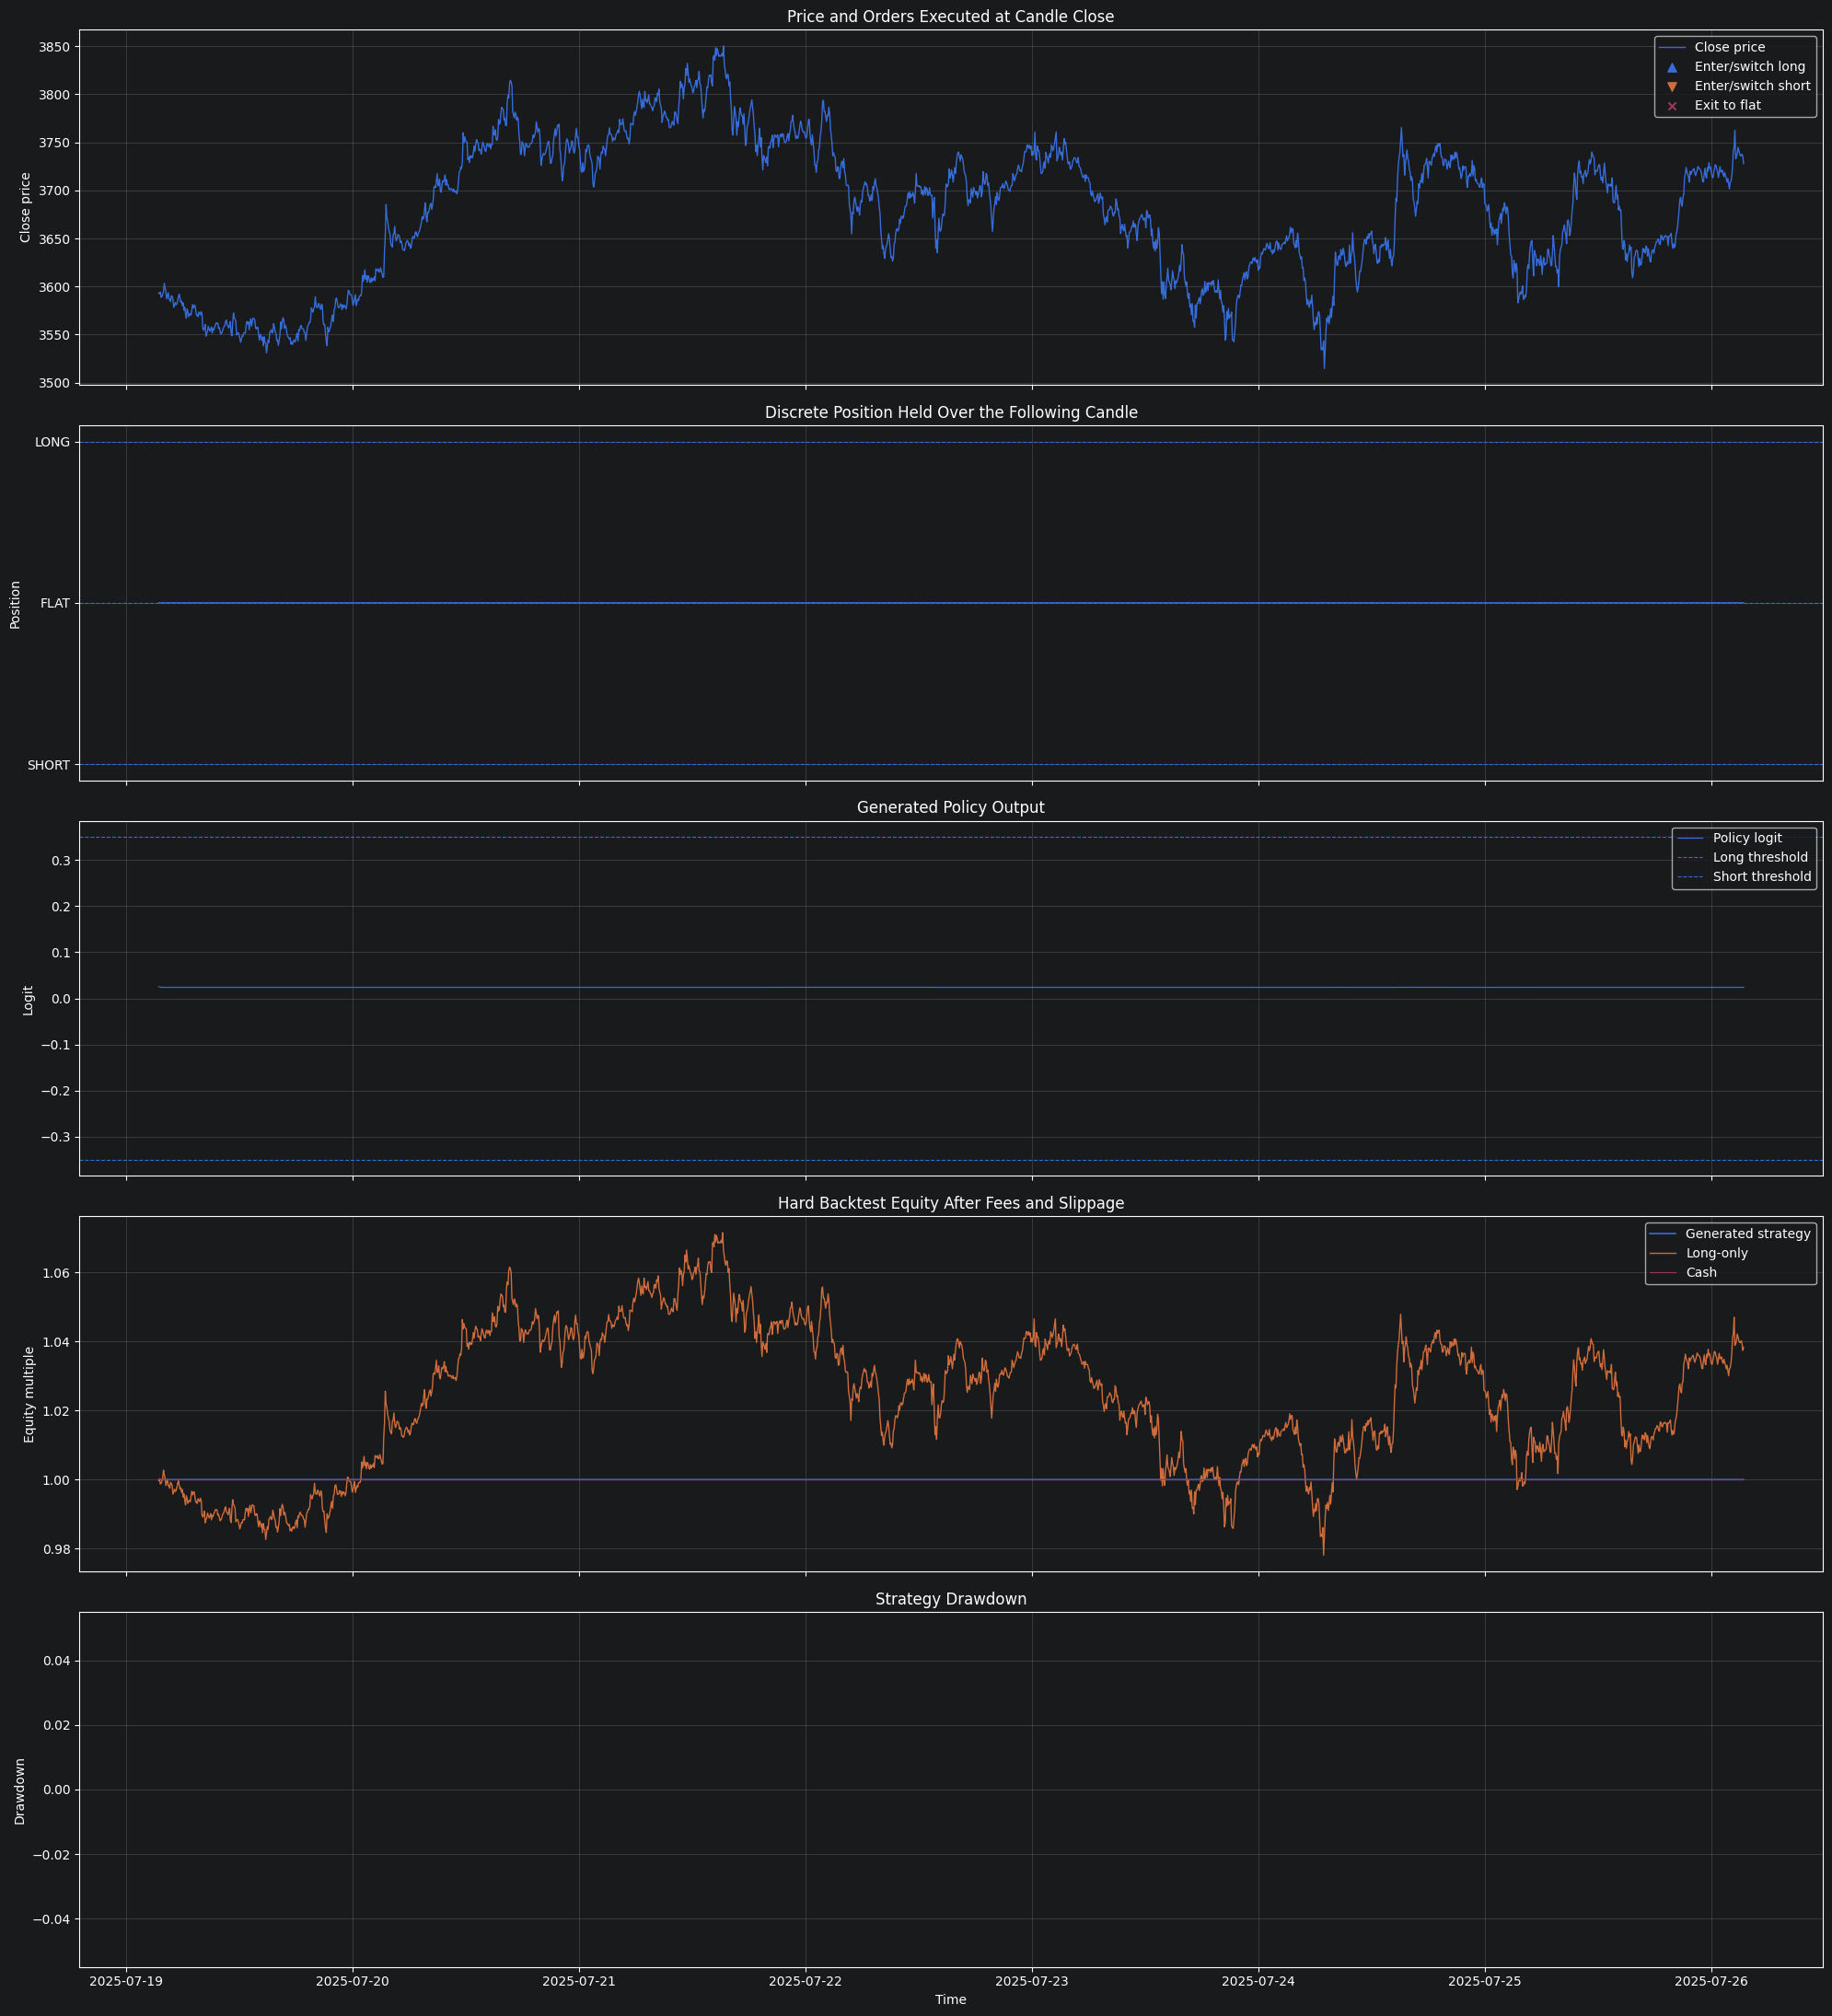

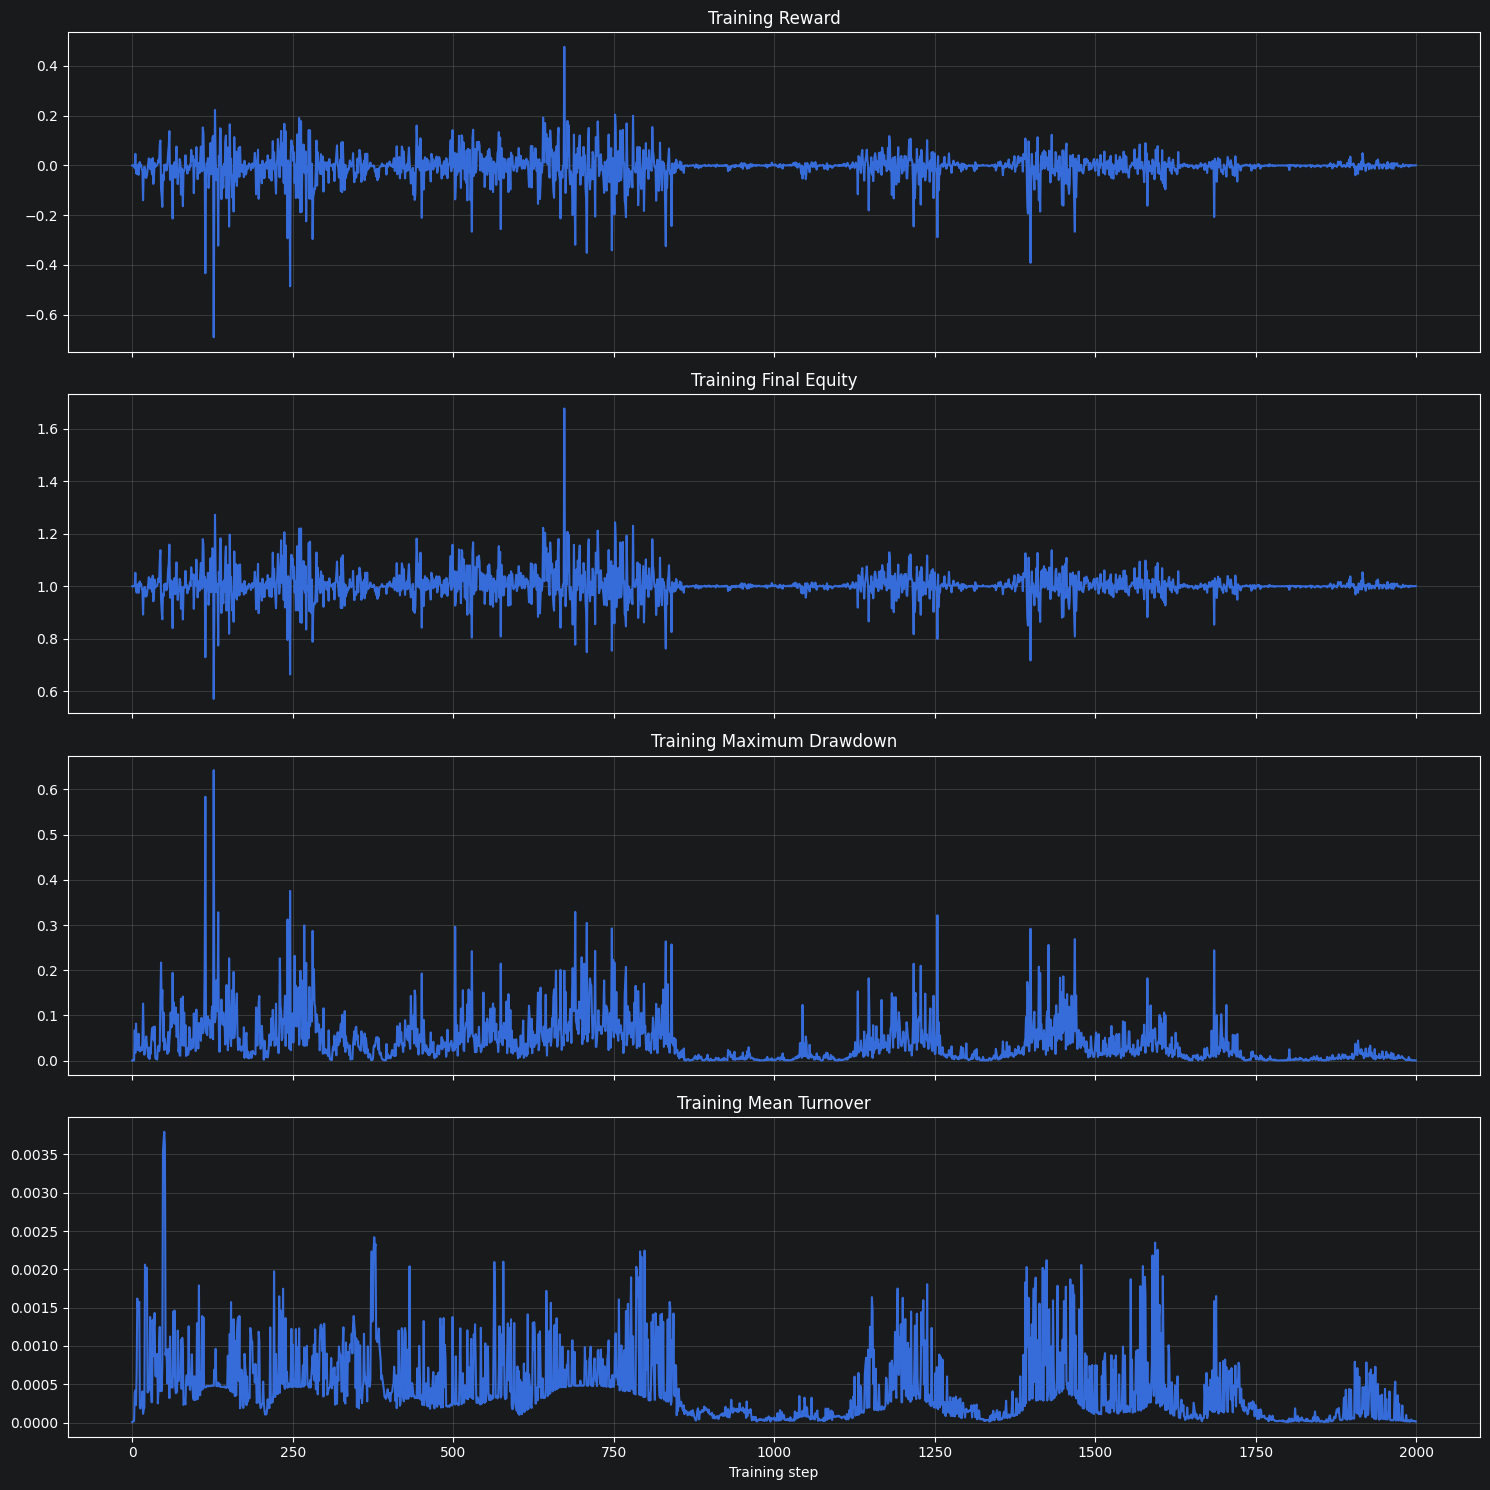

In [7]:
# ============================================================
# TRUE HARD, DETACHED, NO-GRAD BACKTEST
# ============================================================

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


strategy_network.eval()
target_template.eval()

# Select one untouched test episode.
EVAL_START = TEST_START

with torch.no_grad():
    (
        evaluation_past,
        evaluation_future_features,
        evaluation_next_returns,
        evaluation_closes,
    ) = get_episode(
        EVAL_START
    )

    with torch.autocast(
        device_type="cuda",
        dtype=AMP_DTYPE,
    ):
        generated_network = strategy_network(
            evaluation_past,
            freeze=True,
        )

        generated_network.eval()

        logits = generated_network(
            evaluation_future_features
        )

    logits = (
        logits[
            0,
            :,
            0,
        ]
        .float()
    )

    # Exact, discrete action policy.
    hard_positions = torch.where(
        logits > ACTION_THRESHOLD,
        torch.ones_like(logits),
        torch.where(
            logits < -ACTION_THRESHOLD,
            -torch.ones_like(logits),
            torch.zeros_like(logits),
        ),
    )

    previous_positions = torch.cat(
        (
            torch.zeros_like(
                hard_positions[:1]
            ),
            hard_positions[:-1],
        ),
        dim=0,
    )

    hard_orders = (
        hard_positions
        - previous_positions
    )

    turnover = hard_orders.abs()

    next_returns = (
        evaluation_next_returns[
            0
        ].float()
    )

    gross_returns = (
        hard_positions
        * next_returns
    )

    transaction_costs = (
        turnover
        * TOTAL_COST_RATE
    )

    net_returns = (
        gross_returns
        - transaction_costs
    )

    equity = torch.cumprod(
        1.0
        + net_returns.clamp(
            min=-0.95
        ),
        dim=0,
    )

    long_only_equity = torch.cumprod(
        1.0 + next_returns,
        dim=0,
    )

    flat_equity = torch.ones_like(
        equity
    )

    running_peak = equity.cummax(
        dim=0
    ).values

    drawdown = (
        running_peak - equity
    ) / running_peak.clamp_min(1e-8)


# ------------------------------------------------------------
# CPU conversion
# ------------------------------------------------------------

logits_np = (
    logits.cpu().numpy()
)

positions_np = (
    hard_positions.cpu().numpy()
)

previous_positions_np = (
    previous_positions.cpu().numpy()
)

orders_np = (
    hard_orders.cpu().numpy()
)

turnover_np = (
    turnover.cpu().numpy()
)

returns_np = (
    next_returns.cpu().numpy()
)

gross_returns_np = (
    gross_returns.cpu().numpy()
)

costs_np = (
    transaction_costs.cpu().numpy()
)

net_returns_np = (
    net_returns.cpu().numpy()
)

equity_np = (
    equity.cpu().numpy()
)

long_only_equity_np = (
    long_only_equity.cpu().numpy()
)

flat_equity_np = (
    flat_equity.cpu().numpy()
)

drawdown_np = (
    drawdown.cpu().numpy()
)

action_close_prices = (
    evaluation_closes[:-1]
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# Time indices
# ------------------------------------------------------------

future_delta_start = (
    EVAL_START + PAST_WINDOW
)

first_action_close_index = (
    future_delta_start + 1
)

timestamps = pd.to_datetime(
    dataset.df[
        "open_time"
    ].iloc[
        first_action_close_index:
        first_action_close_index
        + FUTURE_WINDOW
    ].to_numpy(),
    unit="ms",
)

if len(timestamps) != FUTURE_WINDOW:
    raise RuntimeError(
        "Timestamp count does not match future window."
    )


# ------------------------------------------------------------
# Order extraction
# ------------------------------------------------------------

order_indices = np.flatnonzero(
    orders_np != 0
)

long_entry_indices = order_indices[
    positions_np[
        order_indices
    ] == 1
]

short_entry_indices = order_indices[
    positions_np[
        order_indices
    ] == -1
]

flat_entry_indices = order_indices[
    positions_np[
        order_indices
    ] == 0
]


def action_name(
    position: float,
) -> str:
    if position > 0:
        return "LONG"

    if position < 0:
        return "SHORT"

    return "FLAT"


orders_table = pd.DataFrame({
    "timestamp": timestamps[
        order_indices
    ],

    "close_price": action_close_prices[
        order_indices
    ],

    "previous_position": (
        previous_positions_np[
            order_indices
        ]
    ),

    "new_position": positions_np[
        order_indices
    ],

    "order_delta": orders_np[
        order_indices
    ],

    "turnover": turnover_np[
        order_indices
    ],

    "action": [
        action_name(position)
        for position in positions_np[
            order_indices
        ]
    ],

    "logit": logits_np[
        order_indices
    ],
})


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

bars_per_year = (
    365 * 24 * 12
)

mean_net_return = (
    net_returns_np.mean()
)

net_return_std = (
    net_returns_np.std()
)

annualized_sharpe = (
    mean_net_return
    / max(net_return_std, 1e-12)
    * math.sqrt(bars_per_year)
)

downside_returns = np.minimum(
    net_returns_np,
    0.0,
)

downside_deviation = np.sqrt(
    np.mean(
        downside_returns**2
    )
)

annualized_sortino = (
    mean_net_return
    / max(downside_deviation, 1e-12)
    * math.sqrt(bars_per_year)
)

final_equity = float(
    equity_np[-1]
)

long_only_final_equity = float(
    long_only_equity_np[-1]
)

total_compounded_return = (
    final_equity - 1.0
)

long_only_return = (
    long_only_final_equity - 1.0
)

maximum_drawdown = float(
    drawdown_np.max()
)

number_of_orders = int(
    len(order_indices)
)

number_of_long_bars = int(
    (positions_np == 1).sum()
)

number_of_short_bars = int(
    (positions_np == -1).sum()
)

number_of_flat_bars = int(
    (positions_np == 0).sum()
)

gross_arithmetic_return = float(
    gross_returns_np.sum()
)

total_transaction_cost = float(
    costs_np.sum()
)

net_arithmetic_return = float(
    net_returns_np.sum()
)

winning_bars = int(
    (net_returns_np > 0).sum()
)

losing_bars = int(
    (net_returns_np < 0).sum()
)

active_bars = (
    winning_bars + losing_bars
)

bar_win_rate = (
    winning_bars
    / max(active_bars, 1)
)


print("HARD DETACHED TEST BACKTEST")
print("=" * 60)
print(f"Episode start:            {EVAL_START:,}")
print(f"Period start:             {timestamps[0]}")
print(f"Period end:               {timestamps[-1]}")
print(f"Final equity:             {final_equity:.6f}")
print(f"Compounded return:        {total_compounded_return:.2%}")
print(f"Long-only return:         {long_only_return:.2%}")
print(f"Maximum drawdown:         {maximum_drawdown:.2%}")
print(f"Annualized Sharpe:        {annualized_sharpe:.3f}")
print(f"Annualized Sortino:       {annualized_sortino:.3f}")
print(f"Gross arithmetic return:  {gross_arithmetic_return:.6f}")
print(f"Transaction costs:        {total_transaction_cost:.6f}")
print(f"Net arithmetic return:    {net_arithmetic_return:.6f}")
print(f"Position changes:         {number_of_orders:,}")
print(f"Long bars:                {number_of_long_bars:,}")
print(f"Short bars:               {number_of_short_bars:,}")
print(f"Flat bars:                {number_of_flat_bars:,}")
print(f"Active-bar win rate:      {bar_win_rate:.2%}")

display(orders_table)


# ------------------------------------------------------------
# Main evaluation plots
# ------------------------------------------------------------

figure, axes = plt.subplots(
    5,
    1,
    figsize=(20, 22),
    sharex=True,
)

# Price and executed orders.
axes[0].plot(
    timestamps,
    action_close_prices,
    linewidth=1.0,
    label="Close price",
)

axes[0].scatter(
    timestamps[
        long_entry_indices
    ],
    action_close_prices[
        long_entry_indices
    ],
    marker="^",
    s=45,
    label="Enter/switch long",
)

axes[0].scatter(
    timestamps[
        short_entry_indices
    ],
    action_close_prices[
        short_entry_indices
    ],
    marker="v",
    s=45,
    label="Enter/switch short",
)

axes[0].scatter(
    timestamps[
        flat_entry_indices
    ],
    action_close_prices[
        flat_entry_indices
    ],
    marker="x",
    s=35,
    label="Exit to flat",
)

axes[0].set_title(
    "Price and Orders Executed at Candle Close"
)

axes[0].set_ylabel(
    "Close price"
)

axes[0].legend()

axes[0].grid(
    True,
    alpha=0.3,
)

# Hard position.
axes[1].step(
    timestamps,
    positions_np,
    where="post",
    linewidth=1.0,
)

axes[1].axhline(
    1.0,
    linestyle="--",
    linewidth=0.8,
)

axes[1].axhline(
    0.0,
    linestyle="--",
    linewidth=0.8,
)

axes[1].axhline(
    -1.0,
    linestyle="--",
    linewidth=0.8,
)

axes[1].set_title(
    "Discrete Position Held Over the Following Candle"
)

axes[1].set_ylabel(
    "Position"
)

axes[1].set_yticks(
    [-1, 0, 1]
)

axes[1].set_yticklabels(
    ["SHORT", "FLAT", "LONG"]
)

axes[1].grid(
    True,
    alpha=0.3,
)

# Raw policy logit and thresholds.
axes[2].plot(
    timestamps,
    logits_np,
    linewidth=0.9,
    label="Policy logit",
)

axes[2].axhline(
    ACTION_THRESHOLD,
    linestyle="--",
    linewidth=0.8,
    label="Long threshold",
)

axes[2].axhline(
    -ACTION_THRESHOLD,
    linestyle="--",
    linewidth=0.8,
    label="Short threshold",
)

axes[2].set_title(
    "Generated Policy Output"
)

axes[2].set_ylabel(
    "Logit"
)

axes[2].legend()

axes[2].grid(
    True,
    alpha=0.3,
)

# Equity.
axes[3].plot(
    timestamps,
    equity_np,
    linewidth=1.2,
    label="Generated strategy",
)

axes[3].plot(
    timestamps,
    long_only_equity_np,
    linewidth=1.0,
    label="Long-only",
)

axes[3].plot(
    timestamps,
    flat_equity_np,
    linewidth=0.8,
    label="Cash",
)

axes[3].set_title(
    "Hard Backtest Equity After Fees and Slippage"
)

axes[3].set_ylabel(
    "Equity multiple"
)

axes[3].legend()

axes[3].grid(
    True,
    alpha=0.3,
)

# Drawdown.
axes[4].fill_between(
    timestamps,
    -drawdown_np,
    0.0,
    alpha=0.5,
)

axes[4].set_title(
    "Strategy Drawdown"
)

axes[4].set_ylabel(
    "Drawdown"
)

axes[4].set_xlabel(
    "Time"
)

axes[4].grid(
    True,
    alpha=0.3,
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Training curves
# ------------------------------------------------------------

training_figure, training_axes = plt.subplots(
    4,
    1,
    figsize=(15, 15),
    sharex=True,
)

training_axes[0].plot(
    training_history["reward"]
)

training_axes[0].set_title(
    "Training Reward"
)

training_axes[0].grid(
    True,
    alpha=0.3,
)

training_axes[1].plot(
    training_history["equity"]
)

training_axes[1].set_title(
    "Training Final Equity"
)

training_axes[1].grid(
    True,
    alpha=0.3,
)

training_axes[2].plot(
    training_history["drawdown"]
)

training_axes[2].set_title(
    "Training Maximum Drawdown"
)

training_axes[2].grid(
    True,
    alpha=0.3,
)

training_axes[3].plot(
    training_history["turnover"]
)

training_axes[3].set_title(
    "Training Mean Turnover"
)

training_axes[3].set_xlabel(
    "Training step"
)

training_axes[3].grid(
    True,
    alpha=0.3,
)

plt.tight_layout()
plt.show()